# ASRS reports by Primary Problem

*2026-11-15*

How often each **Primary Problem** occurs in the NASA ASRS public database, across all reports and in the latest 20,000, and prepares the report narratives for text classification. The Primary Problem is the ASRS analyst's assessment of the most prominent factor in a report.

## Data

Source: NASA ASRS Database Online, [Query Wizard](https://dbol1-prod.arc.nasa.gov/ASRSPublicQueryWizard/QueryWizard_Filter.aspx). The wizard exports at most 5,000 reports at a time, so the data was collected in date windows:

- **Jan 2024 – Aug 2026**: five exports made earlier from the wizard (`data/2024-01-07.csv`, `2024-08-12.csv`, `2025-01-07.csv`, `2025-08-12.csv`, `2026.csv`).
- **Jan 1988 – Dec 2023**: downloaded with `download_asrs.py`, which drives the wizard over HTTP in 6-month windows filtered on *Date of Incident* (1988 is where the database starts). The range holds 228,368 reports in 74 files. The two half-years over the 5,000 limit (Jan–Jun 1995 and Jan–Jun 1999) were split into quarters.
- `merge_csv.py` combined all exports into `data/merged.csv`, keeping each report (ACN) once.

```
python download_asrs.py   # Jan 1988 – Dec 2023 -> data/
python merge_csv.py       # data/*.csv -> data/merged.csv
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter

# Works when run from notebooks/ or from the repository root.
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA = ROOT / "data" / "merged.csv"
FIGURES = ROOT / "figures"

COLUMN = "Primary Problem"
LATEST = 20_000  # size of the "latest reports" sample

In [2]:
# ASRS exports have two header rows; the second holds the column names.
df = pd.read_csv(DATA, header=1, usecols=["ACN", "Date", COLUMN], dtype=str)
df = df.dropna(how="all").drop_duplicates(subset="ACN")
df["date"] = pd.to_datetime(df["Date"], format="%Y%m", errors="coerce")  # month of the incident
df["acn"] = df["ACN"].astype(int)  # report number, assigned in order of receipt


def period(frame):
    return f"{frame['date'].min():%b %Y} – {frame['date'].max():%b %Y}"


print(f"{len(df):,} reports, {period(df)}")

243,290 reports, Jan 1988 – Aug 2026


## Counting and plotting

- A few reports list more than one primary problem, e.g. `Human Factors; Procedure`. Each distinct value counts once for that report, so the counts add up to slightly more than the number of reports.
- Reports with no primary problem are counted separately and left out of the charts.
- Shares are relative to the reports that have a primary problem recorded.

In [3]:
def count_values(frame):
    """Reports per primary problem (most frequent first), reports with a value, reports without."""
    values = frame[COLUMN].fillna("").str.strip()
    recorded = values[values != ""]
    per_report = recorded.str.split(";").apply(lambda parts: {p.strip() for p in parts if p.strip()})
    counts = per_report.explode().value_counts()
    counts = counts.sort_index().sort_values(ascending=False, kind="stable")  # ties alphabetical
    return counts, len(recorded), len(values) - len(recorded)


# Light chart theme: one series -> one color, recessive grid and axes.
BAR, SURFACE = "#2a78d6", "#fcfcfb"
TEXT_PRIMARY, TEXT_SECONDARY, TEXT_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10,
})


def plot_counts(counts, recorded, title, subtitle, path):
    """Ranked horizontal bar chart, most frequent on top; shown inline and saved to `path`."""
    n = len(counts)
    fig, ax = plt.subplots(figsize=(10, 1.6 + 0.34 * n))
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)

    ax.barh(range(n), counts.values, height=0.62, color=BAR, zorder=2)
    ax.set_yticks(range(n), counts.index)
    ax.set_ylim(n - 0.5, -0.5)  # most frequent on top

    # Hairline vertical grid, baseline at zero, no box.
    ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(BASELINE)
    ax.tick_params(axis="y", length=0, pad=8, labelcolor=TEXT_SECONDARY, labelsize=10)
    ax.tick_params(axis="x", length=0, labelcolor=TEXT_MUTED, labelsize=9)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_xlabel("Reports", color=TEXT_MUTED, fontsize=9, labelpad=8)
    ax.margins(x=0.14)

    # Direct-label only the leading bar; exact counts are in the tables.
    top = counts.iloc[0]
    ax.annotate(f"{top:,}  ({top / recorded:.0%})", xy=(top, 0), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=TEXT_SECONDARY)

    height = fig.get_figheight()
    fig.text(0.012, 1 - 0.32 / height, title,
             fontsize=14, fontweight="bold", color=TEXT_PRIMARY, va="top")
    fig.text(0.012, 1 - 0.62 / height, subtitle, fontsize=10, color=TEXT_SECONDARY, va="top")
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.85 / height))

    path.parent.mkdir(exist_ok=True)
    fig.savefig(path, dpi=200, facecolor=SURFACE)
    plt.show()

## All reports

In [4]:
counts, recorded, blank = count_values(df)
print(f"{recorded:,} reports with a {COLUMN.lower()}, {blank:,} with none")

table = counts.rename("reports").to_frame()
table["share"] = table["reports"] / recorded
with pd.option_context("display.float_format", "{:.1%}".format):
    display(table)

234,274 reports with a primary problem, 9,016 with none


,reports,share
Primary Problem,,
Human Factors,122633,52.3%
Aircraft,53240,22.7%
Ambiguous,14333,6.1%
Procedure,10446,4.5%
Company Policy,7878,3.4%
Weather,7554,3.2%
Airport,5291,2.3%
ATC Equipment / Nav Facility / Buildings,3245,1.4%
Environment - Non Weather Related,3178,1.4%


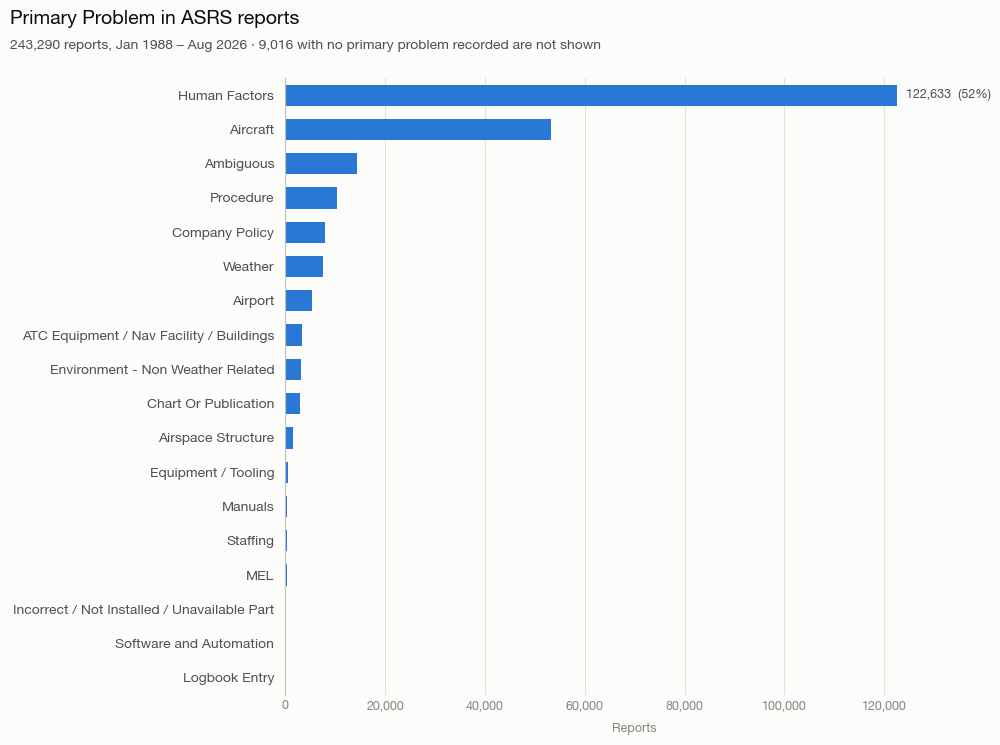

In [5]:
plot_counts(
    counts, recorded,
    title=f"{COLUMN} in ASRS reports",
    subtitle=f"{len(df):,} reports, {period(df)} · "
             f"{blank:,} with no {COLUMN.lower()} recorded are not shown",
    path=FIGURES / "primary_problem_histogram.png",
)

## Latest 20,000 reports

The 20,000 most recent reports by date of incident. Dates are month-only, so the earliest month is only partly included. Within that month, the reports with the highest ACN (the most recently received) are taken. The 21 reports whose date is missing or malformed (e.g. two dates in one field) can't be placed in time and are left out of this sample.

In [6]:
latest = df.sort_values(["date", "acn"], ascending=False).head(LATEST)
counts_latest, recorded_latest, blank_latest = count_values(latest)

first_month = latest["date"].min()
print(f"{len(latest):,} reports, {period(latest)} "
      f"({(latest['date'] == first_month).sum()} of {(df['date'] == first_month).sum()} "
      f"reports from {first_month:%b %Y})")
print(f"{recorded_latest:,} with a {COLUMN.lower()}, {blank_latest:,} with none")

20,000 reports, Nov 2022 – Aug 2026 (85 of 394 reports from Nov 2022)
19,984 with a primary problem, 16 with none


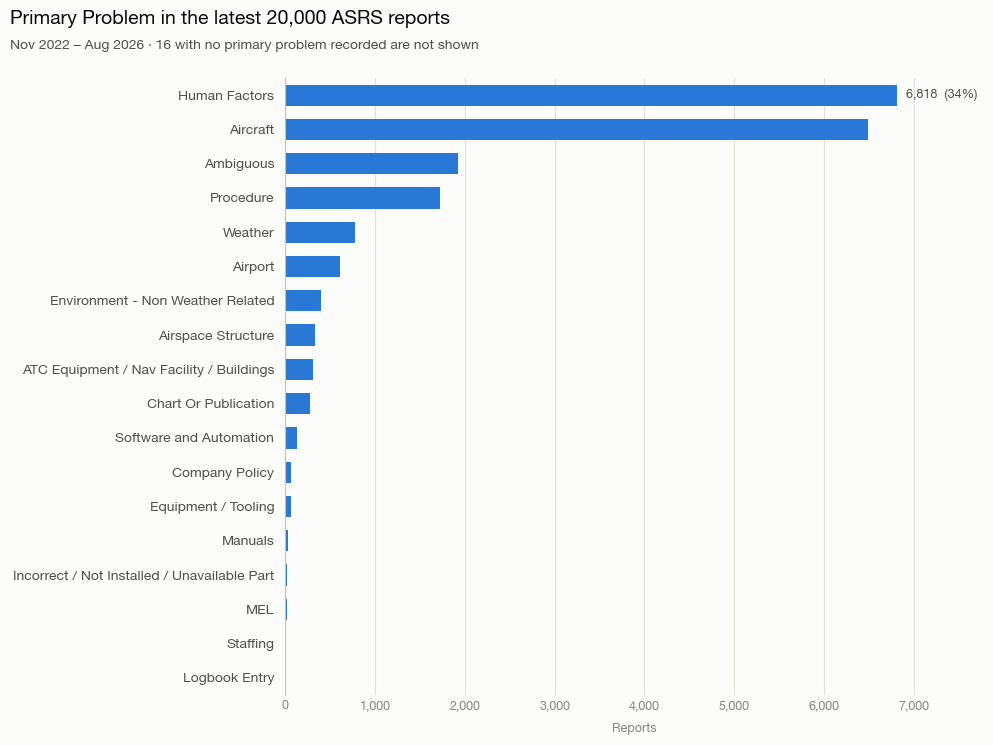

In [7]:
plot_counts(
    counts_latest, recorded_latest,
    title=f"{COLUMN} in the latest {LATEST:,} ASRS reports",
    subtitle=f"{period(latest)}"
             + (f" · {blank_latest:,} with no {COLUMN.lower()} recorded are not shown"
                if blank_latest else ""),
    path=FIGURES / "primary_problem_latest_20k.png",
)

In [8]:
# Share of each primary problem: all reports vs the latest 20,000.
comparison = pd.DataFrame({
    "all reports": counts / recorded,
    f"latest {LATEST:,}": counts_latest / recorded_latest,
}).fillna(0)
comparison["change (pp)"] = (comparison[f"latest {LATEST:,}"] - comparison["all reports"]) * 100
comparison = comparison.sort_values(f"latest {LATEST:,}", ascending=False)
comparison.style.format({"all reports": "{:.1%}", f"latest {LATEST:,}": "{:.1%}",
                         "change (pp)": "{:+.1f}"})

,all reports,"latest 20,000",change (pp)
Primary Problem,,,
Human Factors,52.3%,34.1%,-18.2
Aircraft,22.7%,32.5%,+9.7
Ambiguous,6.1%,9.6%,+3.5
Procedure,4.5%,8.6%,+4.2
Weather,3.2%,3.9%,+0.7
Airport,2.3%,3.0%,+0.8
Environment - Non Weather Related,1.4%,2.0%,+0.6
Airspace Structure,0.7%,1.6%,+0.9
ATC Equipment / Nav Facility / Buildings,1.4%,1.5%,+0.1


## Findings

All reports (Jan 1988 – Aug 2026):

- **Human Factors** is the primary problem in about half of the reports: 122,633, or 52% of the 234,274 reports with a primary problem recorded. That is more than twice the next category, **Aircraft** (53,240; 23%).
- Together, those two account for three quarters (75%) of the reports.
- Ambiguous (6%), Procedure (4%), Company Policy (3%) and Weather (3%) come next. The seven smallest categories (Equipment / Tooling through Logbook Entry) together make up under 1%.
- 9,016 reports (3.7% of 243,290) have no primary problem recorded.

Latest 20,000 reports (Nov 2022 – Aug 2026):

- **Human Factors** and **Aircraft** are almost level: 34% (6,818) and 32% (6,489). Across all years they are 52% and 23%.
- Procedure (8.6%, up from 4.5%) and Ambiguous (9.6%, up from 6.1%) are about twice as common as in the full dataset. Software and Automation rises from 0.1% to 0.7%.
- Company Policy almost disappears: 0.3% (68 reports), against 3.4% across all years.
- Only 16 of the latest reports have no primary problem recorded.
- These shifts may partly reflect changes in how ASRS analysts code reports, not only in what is reported. Checking that would need the trend year by year.

## Narrative preprocessing

This section prepares the narratives for a bag-of-words text classifier, following the preprocessing steps from the Advanced Data Mining lecture.

**Which reports.** The classifier's candidate pool: reports since June 2009 whose single primary problem is Human Factors, Aircraft, Procedure or Weather. Earlier reports are left out for two reasons. Until Dec 2008 the narratives are written entirely in capitals with heavy abbreviation. And the Primary Problem categories changed in mid-2009 (Procedure barely exists before then). A model trained on both eras could learn the era instead of the cause. The text is the reporter's narrative, plus the second reporter's narrative where there is one.

**How the lecture's steps are applied to ASRS narratives**

| Step | What is done | Why it differs from the generic recipe |
|---|---|---|
| ASRS clean-up | Restore numbers (`24;000` → `24000`), expand `n't` to `not`, remove de-identification placeholders (`ZZZ`, `ZZZ1`, `XXL`, `XA:50`) | The CSV export replaced every comma with a semicolon. Placeholders stand for anonymized airports, runways and times and carry no meaning. |
| Standardize text | Expand aviation abbreviations (`FO` → first officer, `PM` → pilot monitoring, `RWY` → runway, `KTS` → knots) | Ambiguous ones (`PM`, `CA`, `FA`) are expanded only when written in capitals, so `3 pm` is left alone. Acronyms that are terms in their own right (ATC, TCAS, QRH) are kept. |
| Correct spelling | Rare lowercase words are replaced by the most frequent word one edit away, if that word appears at least 50 times in these narratives | A general spell-checker would "fix" jargon and names; using the narratives themselves as the dictionary avoids that. |
| Lemmatize, lowercase | WordNet lemmatizer with part-of-speech tags | Tagging needs the original sentence, so it runs before lowercasing and before stop words and punctuation are removed. |
| Remove punctuation, numbers, short words | Keep words of two or more characters | Two-character terms carry meaning here (`ra` = resolution advisory, `n1`). |
| Remove stop words | NLTK's English list, minus negations and directions (`no`, `not`, `above`, `below`, `up`, `down`, `on`, `off`, …), plus `would`, `could`, `also` | "did not descend" vs "descended" and "gear up" vs "gear down" must stay different. |
| Stem | Snowball (Porter2) stemmer applied to the lemmas, saved as a second version | The lecture notes that stemmers work well on lemmatizer output. |

In [9]:
import json
import re
import string
import textwrap
from collections import Counter
from functools import lru_cache

import nltk
from nltk import pos_tag, word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import SnowballStemmer, WordNetLemmatizer

for resource in ["stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng", "punkt_tab"]:
    nltk.download(resource, quiet=True)

CLASSES = ["Human Factors", "Aircraft", "Procedure", "Weather"]
START = pd.Timestamp("2009-06-01")  # one coding scheme and mixed-case narratives from here on

# Outputs go to a subfolder so merge_csv.py, which merges data/*.csv, doesn't pick them up.
PROCESSED = ROOT / "data" / "processed"
PREPARED_PATH = PROCESSED / "narratives_preprocessed.csv"
CORRECTIONS_PATH = PROCESSED / "spelling_corrections.json"

In [10]:
# The second reporter's narrative has the same column name; pandas calls it "Narrative.1".
narratives = pd.read_csv(DATA, header=1, usecols=["ACN", "Narrative", "Narrative.1"], dtype=str)
narratives = narratives.drop_duplicates(subset="ACN").set_index("ACN")

pool = df[(df["date"] >= START) & df[COLUMN].str.strip().isin(CLASSES)].set_index("ACN").join(narratives)
pool = pool[pool["Narrative"].fillna("").str.len() > 50]
texts = (pool["Narrative"] + " " + pool["Narrative.1"].fillna("")).str.strip()

print(f"{len(pool):,} reports since {START:%b %Y}, "
      f"{pool['Narrative.1'].notna().mean():.0%} with a second narrative")
pool[COLUMN].value_counts().to_frame("reports")

70,869 reports since Jun 2009, 23% with a second narrative


,reports
Primary Problem,
Human Factors,30760
Aircraft,26630
Procedure,10270
Weather,3209


In [11]:
# Stop words: NLTK's English list, keeping negations and directions that change the meaning
# of a safety report ("did not descend", "gear up" vs "gear down").
KEEP = {"no", "nor", "not", "against", "above", "below", "up", "down", "on", "off",
        "over", "under", "before", "after", "out"}
STOP_WORDS = (set(stopwords.words("english")) - KEEP) | {"would", "could", "also"}

# Frequent aviation abbreviations, expanded so each concept has one spelling.
ABBREVIATIONS = {
    "acft": "aircraft", "rwy": "runway", "twy": "taxiway", "wx": "weather", "hdg": "heading",
    "kts": "knots", "kt": "knots", "ft": "feet", "fpm": "feet per minute", "nm": "nautical miles",
    "approx": "approximately", "inop": "inoperative", "thru": "through", "nav": "navigation",
    "comm": "communication", "eng": "engine", "hyd": "hydraulic", "mx": "maintenance",
    "maint": "maintenance", "pax": "passengers", "freq": "frequency", "info": "information",
    "pnf": "pilot not flying", "capt": "captain", "f/o": "first officer",
}
# Ambiguous in lower case ("3 pm", "Ca" from "can't"), so expanded only when written in capitals.
UPPERCASE_ABBREVIATIONS = {
    "FO": "first officer", "CA": "captain", "PF": "pilot flying", "PM": "pilot monitoring",
    "FA": "flight attendant", "FAs": "flight attendants", "AP": "autopilot", "ALT": "altitude",
}

# De-identification placeholders: times (XA:50), airports and fixes (ZZZ, ZZZ1),
# runways (XX, XXL, YYR) and codes (XXXX).
PLACEHOLDER = re.compile(r"\b(?:X[A-Z]:\d\d(?:hr)?|Z{2,}\d*|X[A-Z][LRC]?|X{3,}|Y{2,}[LRC]?)\b")
# The CSV export replaced commas with semicolons, also inside numbers ("24;000").
DIGIT_GROUP = re.compile(r"(?<=\d);(?=\d{3}\b)")

In [12]:
def clean_text(text):
    """ASRS-specific clean-up before tokenizing."""
    text = DIGIT_GROUP.sub("", text).replace(";", ",")
    text = re.sub(r"\b([Cc]a)n't\b", r"\1n not", text)   # can't -> can not
    text = re.sub(r"\b([Ww])on't\b", r"\1ill not", text)  # won't -> will not
    text = re.sub(r"n't\b", " not", text)                  # didn't -> did not
    text = PLACEHOLDER.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


def tokenize(text):
    """Split into words and punctuation, expanding abbreviations."""
    tokens = []
    for token in word_tokenize(text):
        full = UPPERCASE_ABBREVIATIONS.get(token) or ABBREVIATIONS.get(token.lower())
        tokens.extend(full.split() if full else [token])
    return tokens


def edits1(word):
    """All strings one deletion, transposition, replacement or insertion away from `word`."""
    letters = string.ascii_lowercase
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = {a + b[1:] for a, b in splits if b}
    transposes = {a + b[1] + b[0] + b[2:] for a, b in splits if len(b) > 1}
    replaces = {a + c + b[1:] for a, b in splits if b for c in letters}
    inserts = {a + c + b for a, b in splits for c in letters}
    return deletes | transposes | replaces | inserts


def build_spelling_corrections(counts, max_rare=2, min_common=50):
    """Map rare non-dictionary words to the most frequent word one edit away."""
    corrections = {}
    for word, n in counts.items():
        if n > max_rare or len(word) < 5 or not word.isalpha() or wordnet.synsets(word):
            continue
        candidates = [(counts[c], c) for c in edits1(word) if counts.get(c, 0) >= min_common]
        if candidates:
            corrections[word] = max(candidates)[1]
    return corrections


def correct_spelling(tokens, corrections):
    # Only lowercase tokens: capitalized ones are mostly names of people, places and products.
    return [corrections.get(t, t) if t.islower() else t for t in tokens]


WORDNET_POS = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}
lemmatizer = WordNetLemmatizer()
stemmer = SnowballStemmer("english")


@lru_cache(maxsize=None)
def lemma(word, tag):
    return lemmatizer.lemmatize(word, WORDNET_POS.get(tag[0], wordnet.NOUN))


def lemmatize(tokens):
    """Lowercased lemmas, using part-of-speech tags from the full sentence."""
    return [lemma(token.lower(), tag) for token, tag in pos_tag(tokens)]


def remove_noise(words):
    """Drop punctuation, numbers, one-character words and stop words."""
    kept = []
    for word in words:
        for part in re.split(r"[^a-z0-9]+", word):  # "and/or" -> "and", "or"
            if len(part) > 1 and not part.isdigit() and part not in STOP_WORDS:
                kept.append(part)
    return kept


@lru_cache(maxsize=None)
def stem(word):
    return stemmer.stem(word)


def preprocess(text, corrections):
    """Full pipeline: narrative -> list of lemmas."""
    tokens = tokenize(clean_text(text))
    return remove_noise(lemmatize(correct_spelling(tokens, corrections)))

### Spelling corrections

Built once from the word counts of all narratives in the pool and saved to `data/processed/spelling_corrections.json`. This takes about 2 minutes. No labels are used, so building it from the whole pool doesn't leak test information.

In [13]:
if CORRECTIONS_PATH.exists():
    corrections = json.loads(CORRECTIONS_PATH.read_text())
else:
    counts = Counter(t.lower() for text in texts for t in tokenize(clean_text(text)))
    corrections = build_spelling_corrections(counts)
    PROCESSED.mkdir(parents=True, exist_ok=True)
    CORRECTIONS_PATH.write_text(json.dumps(corrections, indent=0, sort_keys=True))

examples = pd.Series(corrections).sample(20, random_state=0)
print(f"{len(corrections):,} corrections, for example:")
print(textwrap.fill(", ".join(f"{a} → {b}" for a, b in examples.items()), 110))

2,322 corrections, for example:
caled → called, minot → minor, aprroach → approach, loopb → loop, monitorning → monitoring, alterate →
alternate, batttery → battery, blockf → block, debried → debrief, advided → advised, nevous → nervous, cought
→ caught, unconfortable → uncomfortable, approprate → appropriate, oride → ride, zaircraft → aircraft,
facililty → facility, binos → bins, lasing → losing, inquirey → inquired


### One narrative, step by step

In [14]:
def has(pattern):
    return texts.str.contains(pattern, regex=True)


# A short narrative that exercises the ASRS-specific steps.
example = (texts.str.split().str.len().between(60, 140) & has(r"ZZZ") & has(r"\d;\d{3}")
           & has(r"n't\b") & has(r"\b(?:FO|PF|PM|kts|KTS|RWY)\b"))
acn = max(texts[example].index, key=int)
text = texts[acn]

cleaned = clean_text(text)
tokens = tokenize(cleaned)
corrected = correct_spelling(tokens, corrections)
lemmas = lemmatize(corrected)
words = remove_noise(lemmas)
stages = {
    "1. Raw narrative": text,
    "2. ASRS clean-up (numbers, contractions, placeholders)": cleaned,
    "3. Tokens, abbreviations expanded": " | ".join(tokens),
    "4. Spelling corrections": ", ".join(f"{a} → {b}" for a, b in zip(tokens, corrected) if a != b)
                               or "(none needed)",
    "5. Lemmatized and lowercased": " ".join(lemmas),
    "6. Punctuation, numbers, short and stop words removed": " ".join(words),
    "7. Stemmed": " ".join(stem(w) for w in words),
}
print(f"ACN {acn}, primary problem: {pool.loc[acn, COLUMN]}\n")
for name, value in stages.items():
    print(name)
    print(textwrap.fill(value, 110), end="\n\n")

ACN 2297823, primary problem: Weather

1. Raw narrative
We were cruising at FL 370 in IMC and encountered severe turbulence. The aircraft's altitude initially went
down to 36;700; then up to 37;670; then down to 36;860 before stabilizing at 37;000 again. The FO was PF and
was focused on manually overriding the Autothrottles so we didn't overspeed the aircraft. The autopilot did
not disengage; so he left it on. After we returned to FL 370; I reported the turbulence and altitude deviation
to ZZZ Center. They copied the info and told us to maintain FL 370; but no further communication with us on
the subject. We both had our seatbelts buckled and no one was injured. The aircraft did not sustain any damage
either.

2. ASRS clean-up (numbers, contractions, placeholders)
We were cruising at FL 370 in IMC and encountered severe turbulence. The aircraft's altitude initially went
down to 36700, then up to 37670, then down to 36860 before stabilizing at 37000 again. The FO was PF and was
focused 

### All narratives

The first run takes about 8 minutes. The result is saved to `data/processed/narratives_preprocessed.csv` and loaded from there afterwards. Delete that file and `spelling_corrections.json` to recompute after changing the pipeline. Each row has the report's lemmas and their stems as space-separated text, keyed by ACN.

In [15]:
if PREPARED_PATH.exists():
    prepared = pd.read_csv(PREPARED_PATH, dtype=str).set_index("ACN")
else:
    lemma_lists = []
    for i, narrative in enumerate(texts, 1):
        lemma_lists.append(preprocess(narrative, corrections))
        if i % 10_000 == 0:
            print(f"{i:,} / {len(texts):,}")
    prepared = pd.DataFrame({
        "Date": pool["Date"],
        COLUMN: pool[COLUMN],
        "lemmas": [" ".join(words) for words in lemma_lists],
        "stems": [" ".join(stem(w) for w in words) for words in lemma_lists],
    }, index=texts.index)
    PROCESSED.mkdir(parents=True, exist_ok=True)
    prepared.to_csv(PREPARED_PATH)

prepared.head()

10,000 / 70,869


20,000 / 70,869


30,000 / 70,869


40,000 / 70,869


50,000 / 70,869


60,000 / 70,869


70,000 / 70,869


,Date,Primary Problem,lemmas,stems
ACN,,,,
830651,200906,Human Factors,after hour troubleshoot aircraft miserable wea...,after hour troubleshoot aircraft miser weather...
837511,200906,Human Factors,normal preflight walk around cockpit setup bri...,normal preflight walk around cockpit setup bri...
837512,200906,Human Factors,reason report choose continue visual approach ...,reason report choos continu visual approach la...
837522,200906,Procedure,flight clear takeoff 25r phx fly pilot before ...,flight clear takeoff 25r phx fli pilot befor c...
837524,200906,Procedure,accepted aircraft two new mel captain electric...,accept aircraft two new mel captain electr sea...


In [16]:
raw_words = texts.str.split().str.len()
kept_words = prepared["lemmas"].str.split().str.len()
raw_vocab = len({w for text in texts for w in re.findall(r"[a-z0-9]+", text.lower())})


def vocabulary(docs):
    return len({w for doc in docs for w in doc.split()})


print(f"Words per narrative (median): {raw_words.median():.0f} raw -> {kept_words.median():.0f} preprocessed")
print(f"Vocabulary: {raw_vocab:,} raw lowercase words -> {vocabulary(prepared['lemmas']):,} lemmas "
      f"-> {vocabulary(prepared['stems']):,} stems")

# Most frequent lemmas per class, as a sanity check.
top = {c: [w for w, _ in Counter(w for doc in prepared.loc[prepared[COLUMN] == c, "lemmas"]
                                 for w in doc.split()).most_common(15)]
       for c in CLASSES}
pd.DataFrame(top, index=range(1, 16))

Words per narrative (median): 242 raw -> 132 preprocessed


Vocabulary: 62,292 raw lowercase words -> 53,545 lemmas -> 42,986 stems


,Human Factors,Aircraft,Procedure,Weather
1,on,on,aircraft,on
2,aircraft,aircraft,on,aircraft
3,not,flight,not,not
4,runway,not,runway,flight
5,approach,engine,approach,approach
6,flight,after,flight,weather
7,pilot,no,controller,runway
8,foot,land,traffic,turbulence
9,turn,runway,turn,foot
10,after,maintenance,time,no


## Classification baseline

This section trains the feasibility baseline from `temp/pre-classification.py` on the preprocessed narratives: logistic regression with balanced class weights. It uses two kinds of text features: TF-IDF unigrams and bigrams (up to 3,000 features), as in the original, and Doc2Vec document vectors. The code now lives in the reusable module `classification.py` in the repository root.

- **Test set:** 10% of each class, set aside first, so it has the same class proportions as real reports.
- **Training set:** 20,000 of the remaining reports, with the classes as equal as the data allows: all remaining Weather reports, and the other three classes split evenly.
- **No extra stop words on lemmas and stems.** They were already filtered during preprocessing. scikit-learn's English list would also remove "not", "no", "up", "down", "on" and "off", which the preprocessing keeps on purpose.
- **Metrics:** macro F1, which gives each class equal weight, plus per-class precision and recall. Weather is under 5% of the test set, so its precision will be lower than it would be on a balanced test set.

In [ ]:
import sys

sys.path.insert(0, str(ROOT))  # classification.py lives in the repository root
from classification import (balanced_sample, evaluate, make_doc2vec_pipeline, make_pipeline,
                            plot_confusion_matrix, plot_macro_f1, plot_model_comparison,
                            stratified_holdout, top_features)

TRAIN_SIZE, TEST_SHARE, SEED = 20_000, 0.10, 42

data = prepared.assign(narrative=texts)  # lemmas, stems and the raw narrative, keyed by ACN
rest, test = stratified_holdout(data, COLUMN, test_size=TEST_SHARE, random_state=SEED)
train = balanced_sample(rest, COLUMN, n=TRAIN_SIZE, random_state=SEED)

pd.DataFrame({
    "available": data[COLUMN].value_counts(),
    f"train ({len(train):,})": train[COLUMN].value_counts(),
    f"test ({len(test):,})": test[COLUMN].value_counts(),
})

### TF-IDF features

In [ ]:
pipeline, result = evaluate(train, test, text="lemmas", label=COLUMN,
                            pipeline=make_pipeline(stop_words=None))
print(f"Accuracy {result.accuracy:.3f}, macro F1 {result.macro_f1:.3f}\n")
print(result.report())
ax = plot_confusion_matrix(result, title="TF-IDF features, lemmas")
ax.figure.savefig(FIGURES / "confusion_tfidf_lemmas.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Words and word pairs the model weighs most for each class.
top_features(pipeline, n=15)

### Doc2Vec features

Doc2Vec learns a dense vector for each narrative (100 dimensions here) from the words it contains and the contexts they appear in. Unlike TF-IDF, similar wording maps to nearby vectors even when the exact words differ. It uses the PV-DBOW variant, which usually works best for classifying documents. Vectors for both training and test narratives are inferred the same way, and they're standardized before the logistic regression. Training takes a minute or two.

The dimensions don't correspond to words, so there is no top-features table for this model.

In [ ]:
d2v_pipeline, d2v_result = evaluate(train, test, text="lemmas", label=COLUMN,
                                    pipeline=make_doc2vec_pipeline(vector_size=100, epochs=20, seed=SEED))
print(f"Accuracy {d2v_result.accuracy:.3f}, macro F1 {d2v_result.macro_f1:.3f}\n")
print(d2v_result.report())
ax = plot_confusion_matrix(d2v_result, title="Doc2Vec features, lemmas")
ax.figure.savefig(FIGURES / "confusion_doc2vec_lemmas.png", dpi=200, bbox_inches="tight")
plt.show()

### Which text and which features?

The same split and classifier, with TF-IDF and Doc2Vec features on the raw narrative and on the preprocessed text. For TF-IDF on the raw narrative, scikit-learn's English stop words are removed, as in the original baseline. Doc2Vec gets the raw narrative lowercased and without punctuation, but with its stop words, since it learns from word context. The two lemma models trained above are reused; the other three are trained here, which takes a few minutes.

The table has the exact scores. The first chart compares TF-IDF and Doc2Vec on lemmas class by class, for precision, recall and F1. The second shows the macro F1 of all five combinations.

In [ ]:
results = {"TF-IDF, lemmas": result, "Doc2Vec, lemmas": d2v_result}  # trained above
others = {
    "TF-IDF, raw narrative": ("narrative", make_pipeline(stop_words="english")),
    "TF-IDF, stems": ("stems", make_pipeline(stop_words=None)),
    "Doc2Vec, raw narrative": ("narrative", make_doc2vec_pipeline(seed=SEED)),
}
for name, (column, model) in others.items():
    results[name] = evaluate(train, test, text=column, label=COLUMN, pipeline=model)[1]

order = ["TF-IDF, raw narrative", "TF-IDF, lemmas", "TF-IDF, stems", "Doc2Vec, raw narrative", "Doc2Vec, lemmas"]
scores = pd.DataFrame({
    name: {"accuracy": r.accuracy, "macro F1": r.macro_f1, **r.per_class()["f1"].add_prefix("F1 ").to_dict()}
    for name, r in results.items()
}).T.loc[order]
scores.style.format("{:.3f}")

In [ ]:
fig = plot_model_comparison({"TF-IDF": result, "Doc2Vec": d2v_result},
                            title="TF-IDF vs Doc2Vec, both on lemmas")
fig.savefig(FIGURES / "tfidf_vs_doc2vec_per_class.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
fig = plot_macro_f1({name: results[name] for name in order},
                    groups={name: name.split(",")[0] for name in order},  # color by feature type
                    title="Macro F1 by text version and features")
fig.savefig(FIGURES / "macro_f1_by_variant.png", dpi=200, bbox_inches="tight")
plt.show()